# Seaborn Core Plot Types on Titanic Dataset ()
Reference: [Medium: Seaborn's Core Plot Types by Techie Ashu](https://medium.com/@btech.07/seaborns-core-plot-types-7fefba8a9724)

This notebook covers all 5 core plot families in Seaborn using :
1. **Relational Plots**: , , 
2. **Categorical Plots**: , , , , , , 
3. **Distribution Plots**: , , ,  (Modern Seaborn)
4. **Regression Plots**: , 
5. **Matrix Plots**: , 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


---
## 1. Relational Plots
Used to visualize relationships between numerical variables.

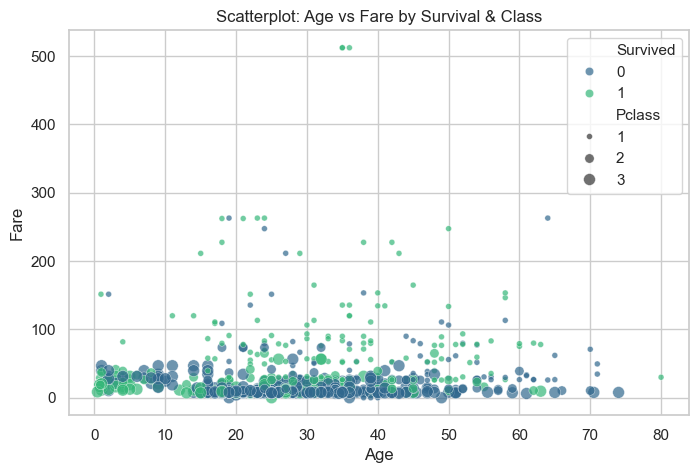

In [2]:
# 1.1 Scatterplot: Age vs Fare, colored by Survived and sized by Pclass
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Age", y="Fare", hue="Survived", size="Pclass", palette="viridis", alpha=0.7)
plt.title("Scatterplot: Age vs Fare by Survival & Class")
plt.show()

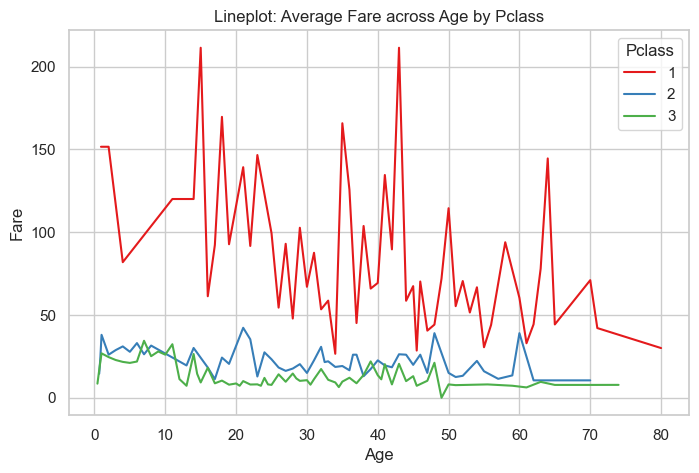

In [3]:
# 1.2 Lineplot: Fare trend across Age by Pclass
plt.figure(figsize=(8, 5))
sns.lineplot(data=df, x="Age", y="Fare", hue="Pclass", palette="Set1", errorbar=None)
plt.title("Lineplot: Average Fare across Age by Pclass")
plt.show()

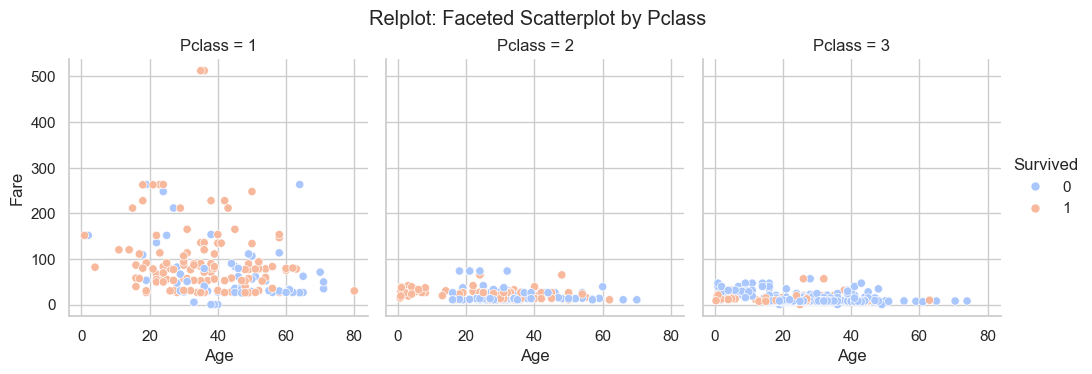

In [4]:
# 1.3 Relplot (Figure-level): Faceted scatterplot across classes
g = sns.relplot(data=df, x="Age", y="Fare", hue="Survived", col="Pclass", kind="scatter", palette="coolwarm", height=3.8, aspect=0.9)
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle("Relplot: Faceted Scatterplot by Pclass")
plt.show()

---
## 2. Categorical Plots
Used to visualize relationships involving categorical variables.

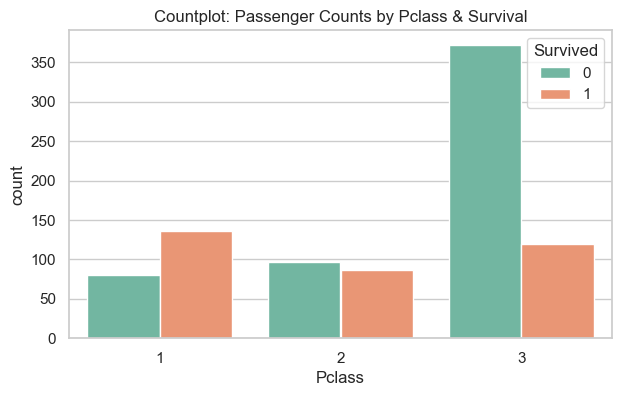

In [5]:
# 2.1 Countplot: Passenger counts by Class and Survival
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Pclass", hue="Survived", palette="Set2")
plt.title("Countplot: Passenger Counts by Pclass & Survival")
plt.show()

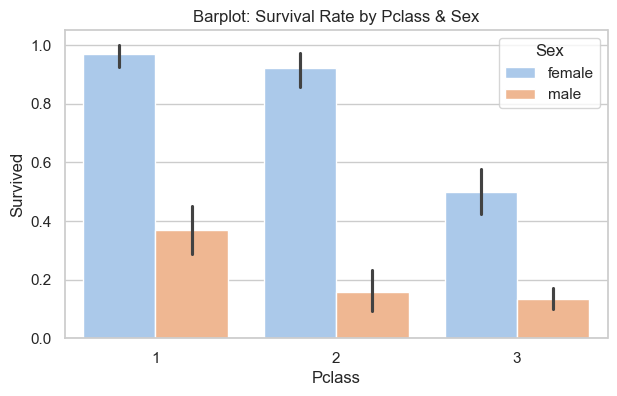

In [6]:
# 2.2 Barplot: Mean survival rate by Class and Sex
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", palette="pastel")
plt.title("Barplot: Survival Rate by Pclass & Sex")
plt.show()

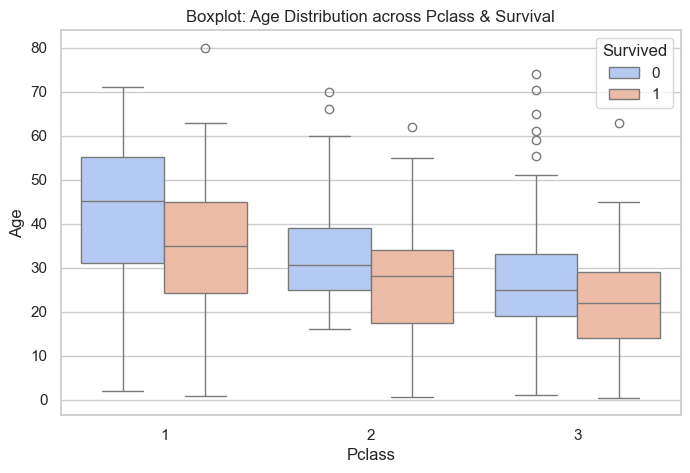

In [7]:
# 2.3 Boxplot: Age distribution across Class and Survival
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Pclass", y="Age", hue="Survived", palette="coolwarm")
plt.title("Boxplot: Age Distribution across Pclass & Survival")
plt.show()

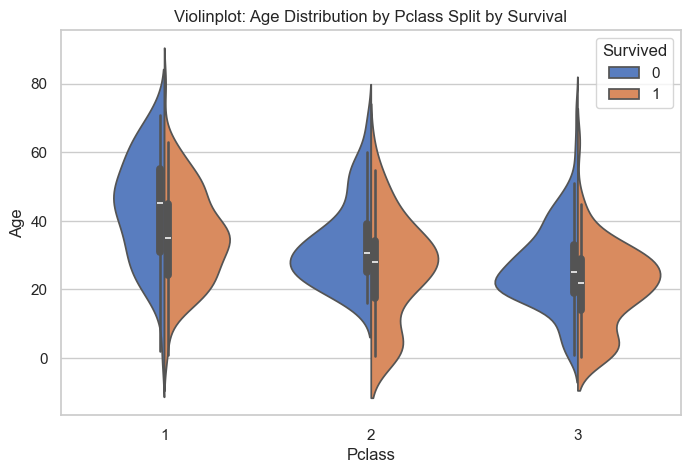

In [8]:
# 2.4 Violinplot: Age density split by Survival
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x="Pclass", y="Age", hue="Survived", split=True, palette="muted")
plt.title("Violinplot: Age Distribution by Pclass Split by Survival")
plt.show()

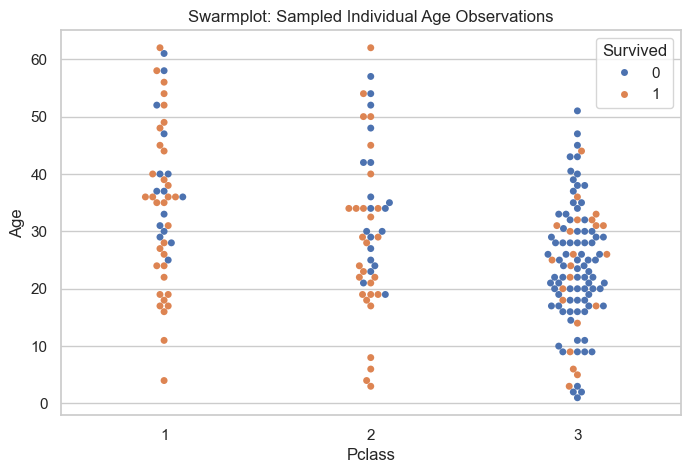

In [9]:
# 2.5 Swarmplot: Sampled individual data points
plt.figure(figsize=(8, 5))
sample_df = df.dropna(subset=["Age"]).sample(n=200, random_state=42)
sns.swarmplot(data=sample_df, x="Pclass", y="Age", hue="Survived", palette="deep", size=5)
plt.title("Swarmplot: Sampled Individual Age Observations")
plt.show()

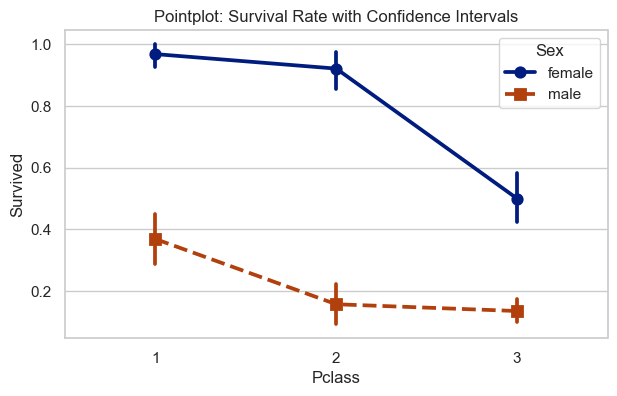

In [10]:
# 2.6 Pointplot: Survival rate estimates and confidence intervals
plt.figure(figsize=(7, 4))
sns.pointplot(data=df, x="Pclass", y="Survived", hue="Sex", palette="dark", markers=["o", "s"], linestyles=["-", "--"])
plt.title("Pointplot: Survival Rate with Confidence Intervals")
plt.show()

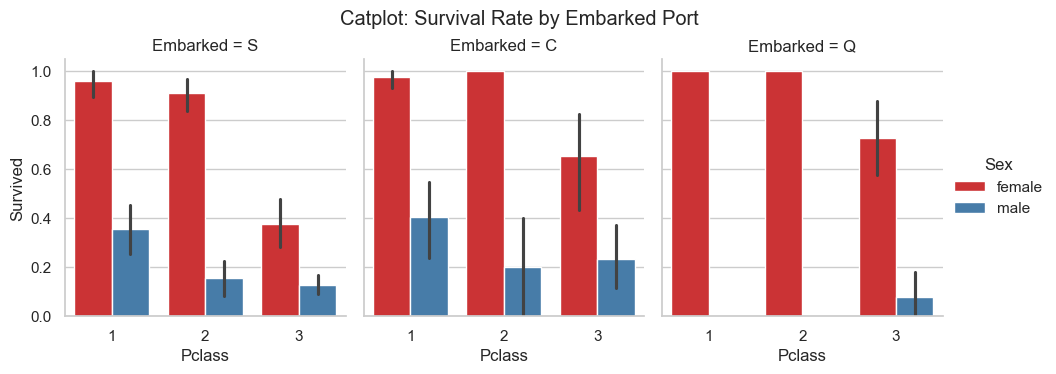

In [11]:
# 2.7 Catplot (Figure-level): Faceted barplot across Embarked ports
g = sns.catplot(data=df.dropna(subset=["Embarked"]), x="Pclass", y="Survived", hue="Sex", col="Embarked", kind="bar", palette="Set1", height=3.8, aspect=0.85)
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle("Catplot: Survival Rate by Embarked Port")
plt.show()

---
## 3. Distribution Plots
Modern distribution functions in Seaborn (replacing deprecated ).

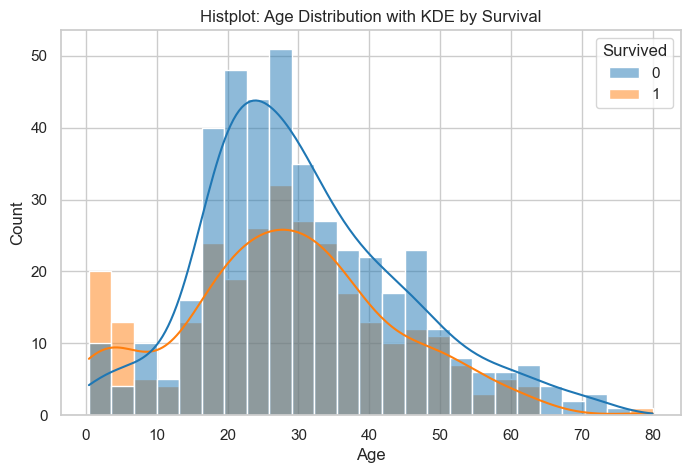

In [12]:
# 3.1 Histplot with KDE (modern replacement for distplot)
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", kde=True, hue="Survived", bins=25, palette="tab10")
plt.title("Histplot: Age Distribution with KDE by Survival")
plt.show()

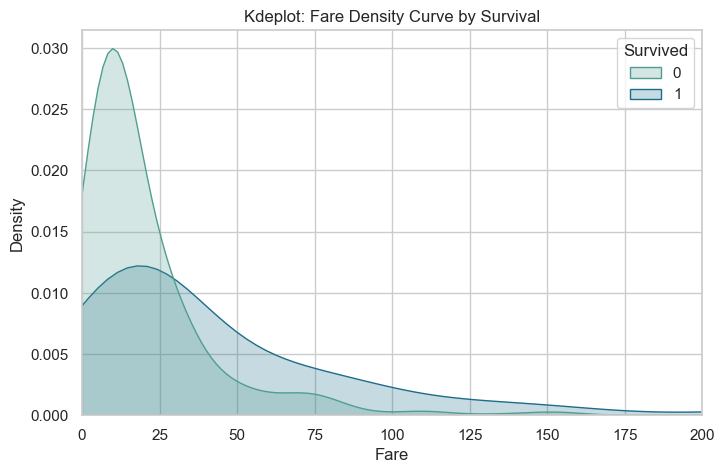

In [13]:
# 3.2 Kdeplot: Fare density curve
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x="Fare", hue="Survived", fill=True, common_norm=False, palette="crest")
plt.xlim(0, 200)
plt.title("Kdeplot: Fare Density Curve by Survival")
plt.show()

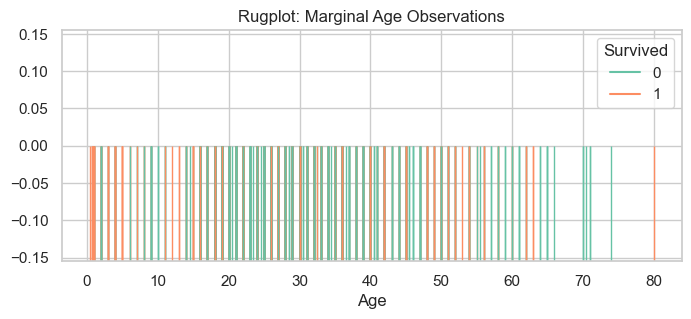

In [14]:
# 3.3 Rugplot: Marginal observation ticks
plt.figure(figsize=(8, 3))
sns.rugplot(data=df, x="Age", hue="Survived", height=0.5, palette="Set2")
plt.title("Rugplot: Marginal Age Observations")
plt.show()

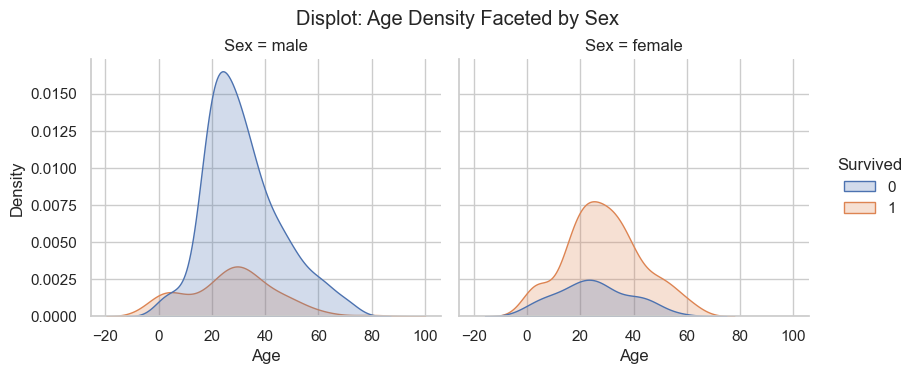

In [15]:
# 3.4 Displot (Figure-level): Faceted KDE density distribution
g = sns.displot(data=df, x="Age", hue="Survived", kind="kde", fill=True, col="Sex", height=3.8, aspect=1.1)
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle("Displot: Age Density Faceted by Sex")
plt.show()

---
## 4. Regression Plots
Visualizing linear relationships and trends.

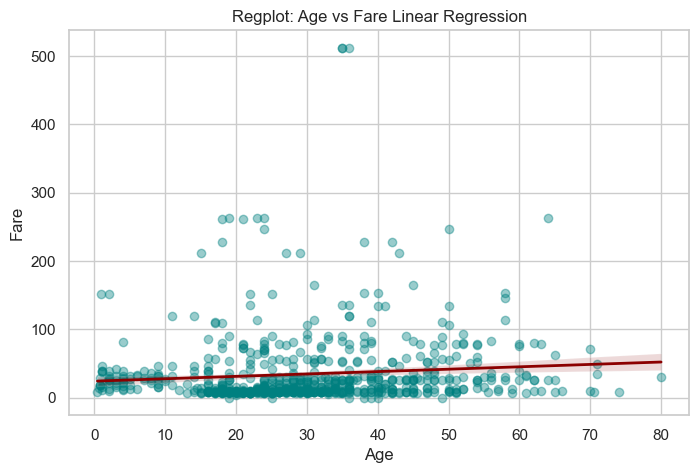

In [16]:
# 4.1 Regplot: Age vs Fare linear regression
plt.figure(figsize=(8, 5))
clean_df = df.dropna(subset=["Age", "Fare"])
sns.regplot(data=clean_df, x="Age", y="Fare", scatter_kws={"alpha": 0.4, "color": "teal"}, line_kws={"color": "darkred", "linewidth": 2})
plt.title("Regplot: Age vs Fare Linear Regression")
plt.show()

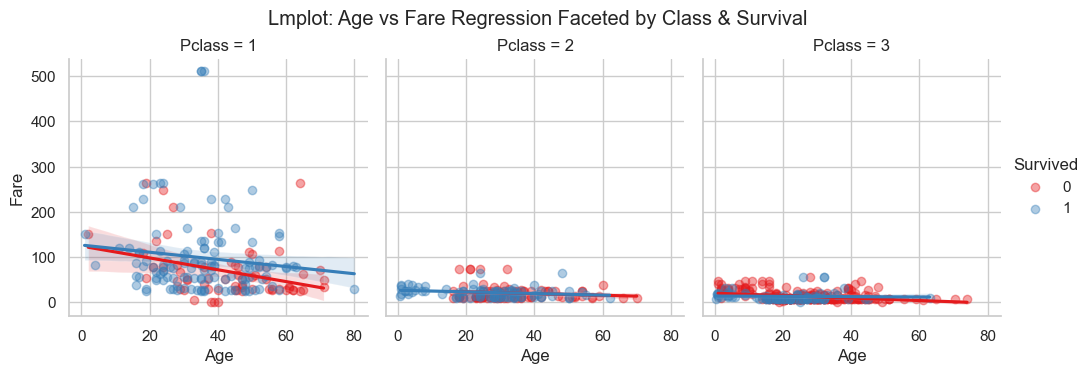

In [17]:
# 4.2 Lmplot (Figure-level): Faceted regression across Pclass
g = sns.lmplot(data=clean_df, x="Age", y="Fare", hue="Survived", col="Pclass", palette="Set1", scatter_kws={"alpha": 0.4}, height=3.8, aspect=0.9)
g.fig.subplots_adjust(top=0.85)
g.fig.suptitle("Lmplot: Age vs Fare Regression Faceted by Class & Survival")
plt.show()

---
## 5. Matrix Plots
Correlation heatmaps and hierarchical clustering.

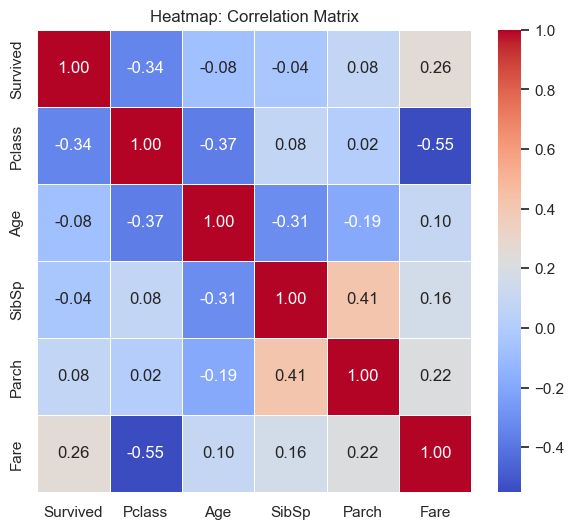

In [18]:
# 5.1 Heatmap: Correlation matrix of numeric features
num_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
corr = df[num_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, cbar=True)
plt.title("Heatmap: Correlation Matrix")
plt.show()

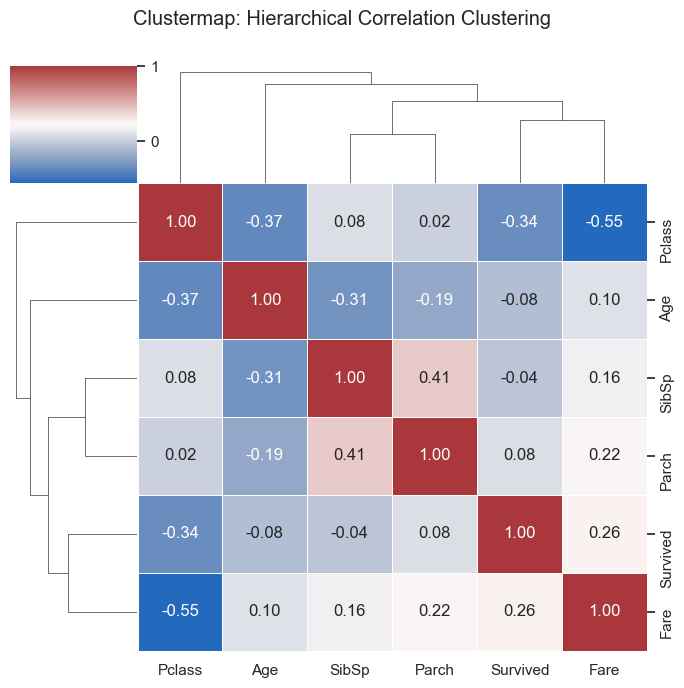

In [19]:
# 5.2 Clustermap: Hierarchical correlation clustering
cm = sns.clustermap(corr, annot=True, cmap="vlag", fmt=".2f", figsize=(7, 7), linewidths=0.5)
cm.fig.subplots_adjust(top=0.9)
cm.fig.suptitle("Clustermap: Hierarchical Correlation Clustering")
plt.show()